<a href="https://colab.research.google.com/github/Theresa-Gao-0529/MSSP607/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AdventureWorks Internet Sales Case Study



In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from urllib.parse import quote

FIGURES_DIR = Path('figures')
FIGURES_DIR.mkdir(exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.style.use('seaborn-v0_8-whitegrid')

In [3]:
# The CSV files are stored in the public GitHub repository under data/Assignment 2.
# GitHub Raw URLs work in both Google Colab and local Jupyter notebooks.
# The repository must be public for unauthenticated Raw URL access.
OWNER = 'Theresa-Gao-0529'
REPOSITORY = 'MSSP607'
repo_url = f'https://github.com/{OWNER}/{REPOSITORY}'
BRANCH = 'main'
GITHUB_FOLDER = 'data/Assignment 2'
USE_GITHUB = True

def github_raw_url(name):
    folder = quote(GITHUB_FOLDER, safe='/')
    return f'https://raw.githubusercontent.com/{OWNER}/{REPOSITORY}/{BRANCH}/{folder}/{quote(name)}'

def locate_local(name):
    candidates = [
        Path(name),
        Path('data') / name,
        Path('data') / 'Assignment 2' / name,
        Path('/private/tmp') / name,
    ]
    for path in candidates:
        if path.exists():
            return path
    return None

def source_for(name):
    if USE_GITHUB:
        return github_raw_url(name)
    local = locate_local(name)
    if local is None:
        raise FileNotFoundError(f'Missing {name}. Set USE_GITHUB=True or place it in data/Assignment 2/.')
    return local

def read_source_csv(name, **kwargs):
    source = source_for(name)
    try:
        return pd.read_csv(source, **kwargs)
    except Exception as exc:
        local = locate_local(name)
        if USE_GITHUB and local is not None:
            print(f'GitHub read failed for {name}; using local copy: {local}')
            return pd.read_csv(local, **kwargs)
        raise exc

files = {name: source_for(name) for name in [
    'Internet Sales.csv', 'Date.csv', 'Product.csv', 'DimCustomer.csv',
    'DimGeography.csv', 'DimProduct_official.csv'
]}
print('Data source:', 'GitHub Raw' if USE_GITHUB else 'local files')
files

Data source: GitHub Raw


{'Internet Sales.csv': 'https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/Assignment%202/Internet%20Sales.csv',
 'Date.csv': 'https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/Assignment%202/Date.csv',
 'Product.csv': 'https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/Assignment%202/Product.csv',
 'DimCustomer.csv': 'https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/Assignment%202/DimCustomer.csv',
 'DimGeography.csv': 'https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/Assignment%202/DimGeography.csv',
 'DimProduct_official.csv': 'https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/Assignment%202/DimProduct_official.csv'}

In [4]:
sales = read_source_csv('Internet Sales.csv')
sales.columns = [c.replace('\ufeff', '') for c in sales.columns]
dates = read_source_csv('Date.csv')
dates.columns = [c.replace('\ufeff', '') for c in dates.columns]
products = read_source_csv('Product.csv')
products.columns = [c.replace('\ufeff', '') for c in products.columns]
customers = read_source_csv('DimCustomer.csv', sep='|', header=None, usecols=[0, 1, 11, 13, 22], names=['CustomerKey','GeographyKey','Gender','YearlyIncome','HouseOwnerFlag'])
geography = read_source_csv('DimGeography.csv', sep='|', header=None, usecols=[0, 5], names=['GeographyKey','CountryRegion'])
dim_product = read_source_csv('DimProduct_official.csv', sep='|', header=None, usecols=[0, 13], names=['ProductKey','ListPrice'])
for c in ['ProductKey','OrderDateKey','CustomerKey']:
    sales[c] = pd.to_numeric(sales[c])
dates['DateKey'] = pd.to_numeric(dates['DateKey'])
dates['Year'] = pd.to_numeric(dates['Year'])
for c in ['CustomerKey','GeographyKey','YearlyIncome','HouseOwnerFlag']:
    customers[c] = pd.to_numeric(customers[c], errors='coerce')
customers['Gender'] = customers['Gender'].astype('string').str.strip()
geography['GeographyKey'] = pd.to_numeric(geography['GeographyKey'])
products['ProductKey'] = pd.to_numeric(products['ProductKey'])
dim_product['ProductKey'] = pd.to_numeric(dim_product['ProductKey'])
dim_product['ListPrice'] = pd.to_numeric(dim_product['ListPrice'], errors='coerce')
print(f'Sales rows: {len(sales):,}; date range: {sales.OrderDateKey.min()}–{sales.OrderDateKey.max()}; total sales: ${sales["Sales Amount"].sum():,.2f}')

Sales rows: 60,384; date range: 20200101–20230128; total sales: $29,315,256.18


In [5]:
# Join the fact table to date, customer, geography, and product dimensions.
analysis = (sales
    .merge(dates[['DateKey','Year']], left_on='OrderDateKey', right_on='DateKey', validate='many_to_one')
    .merge(customers, on='CustomerKey', validate='many_to_one')
    .merge(geography, on='GeographyKey', validate='many_to_one')
    .merge(products[['ProductKey','Product Category']], on='ProductKey', validate='many_to_one')
    .merge(dim_product, on='ProductKey', validate='many_to_one')
)
analysis.head()

,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,CustomerKey,Sales Order Number,Sales Amount,DateKey,Year,GeographyKey,Gender,YearlyIncome,HouseOwnerFlag,CountryRegion,Product Category,ListPrice
0,314,20200101,20200113,20200108,27606,SO43711,"3,578.27",20200101,2020,545,F,"70,000.00",0,United States,Bikes,"3,578.27"
1,311,20200101,20200113,20200108,13513,SO43712,"3,578.27",20200101,2020,162,F,"30,000.00",1,Germany,Bikes,"3,578.27"
2,310,20200102,20200114,20200109,27601,SO43713,"3,578.27",20200102,2020,301,F,"60,000.00",0,United States,Bikes,"3,578.27"
3,311,20200102,20200114,20200109,13591,SO43714,"3,578.27",20200102,2020,278,F,"170,000.00",1,United Kingdom,Bikes,"3,578.27"
4,314,20200102,20200114,20200109,16483,SO43715,"3,578.27",20200102,2020,35,M,"40,000.00",1,Australia,Bikes,"3,578.27"


## 1. Internet Sales by Country Region and Year

,CountryRegion,Year,Internet Sales
0,Australia,2020,"2,563,732.25"
1,Australia,2021,"2,128,407.46"
2,Australia,2022,"4,339,443.38"
3,Australia,2023,"8,507.72"
4,Canada,2020,"571,571.80"
5,Canada,2021,"307,604.52"
6,Canada,2022,"1,085,632.65"
7,Canada,2023,"9,457.62"
8,France,2020,"410,845.33"
9,France,2021,"648,065.54"


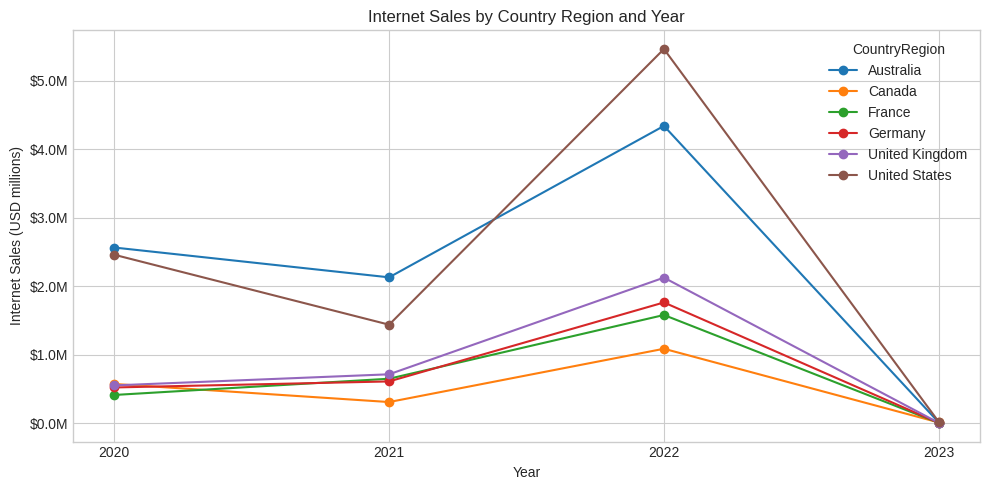

In [6]:
country_year = (analysis.groupby(['CountryRegion','Year'], as_index=False)['Sales Amount']
    .sum().rename(columns={'Sales Amount':'Internet Sales'}).sort_values(['CountryRegion','Year']))
display(country_year)
fig, ax = plt.subplots(figsize=(10, 5))
country_year.pivot(index='Year', columns='CountryRegion', values='Internet Sales').plot(marker='o', ax=ax, title='Internet Sales by Country Region and Year')
ax.set_ylabel('Internet Sales (USD millions)')
ax.set_xticks(sorted(country_year['Year'].unique()))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x/1_000_000:.1f}M'))
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'country_year_sales.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Yearly Income Statistics by Country Region and Gender

In [7]:
income_stats = (customers.merge(geography, on='GeographyKey')
    .groupby(['CountryRegion','Gender'])['YearlyIncome']
    .agg(N='count', Min='min', Max='max', Std_Dev='std').reset_index())
display(income_stats)

,CountryRegion,Gender,N,Min,Max,Std_Dev
0,Australia,F,1777,"10,000.00","160,000.00","31,164.36"
1,Australia,M,1814,"10,000.00","170,000.00","32,450.71"
2,Canada,F,767,"10,000.00","170,000.00","19,181.55"
3,Canada,M,804,"10,000.00","170,000.00","21,214.77"
4,France,F,893,"10,000.00","110,000.00","26,915.85"
5,France,M,917,"10,000.00","110,000.00","27,633.45"
6,Germany,F,874,"10,000.00","130,000.00","35,715.76"
7,Germany,M,906,"10,000.00","130,000.00","35,277.49"
8,United Kingdom,F,934,"10,000.00","170,000.00","48,288.44"
9,United Kingdom,M,979,"10,000.00","170,000.00","48,593.22"


## 3. Highest Sales Product Category and Average List Price

Average Bikes ListPrice: $1,524.59


,Product Category,Internet_Sales,Sales_Lines
1,Bikes,"28,274,723.61",15191
0,Accessories,"700,759.96",36092
2,Clothing,"339,772.61",9101


Bikes share of recorded sales: 96.45%


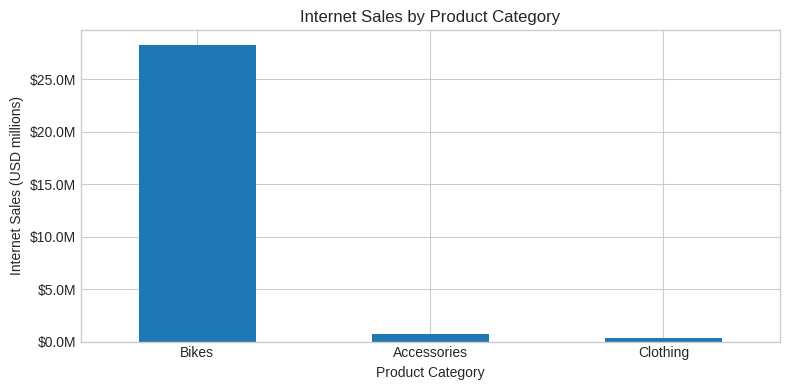

In [8]:
category_sales = (analysis.groupby('Product Category', as_index=False)
    .agg(Internet_Sales=('Sales Amount','sum'), Sales_Lines=('Sales Amount','size'))
    .sort_values('Internet_Sales', ascending=False))
bike_price = dim_product.merge(products[['ProductKey','Product Category']], on='ProductKey')
bike_price = bike_price[bike_price['Product Category'].eq('Bikes')]
print(f'Average Bikes ListPrice: ${bike_price.ListPrice.mean():,.2f}')
display(category_sales)
print(f'Bikes share of recorded sales: {category_sales.iloc[0].Internet_Sales / analysis["Sales Amount"].sum():.2%}')
fig, ax = plt.subplots(figsize=(8, 4))
category_sales.plot.bar(x='Product Category', y='Internet_Sales', legend=False, ax=ax, title='Internet Sales by Product Category')
ax.set_ylabel('Internet Sales (USD millions)')
ax.tick_params(axis='x', labelrotation=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x/1_000_000:.1f}M'))
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'category_sales.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Home Ownership and Sales

,Group,Sales,Lines,Orders,Customers,Avg_Line,Avg_Order
0,Non-homeowner,"8,955,792.63",18694,8596,5981,479.07,"1,041.86"
1,Homeowner,"20,359,463.55",41690,19049,12502,488.35,"1,068.79"


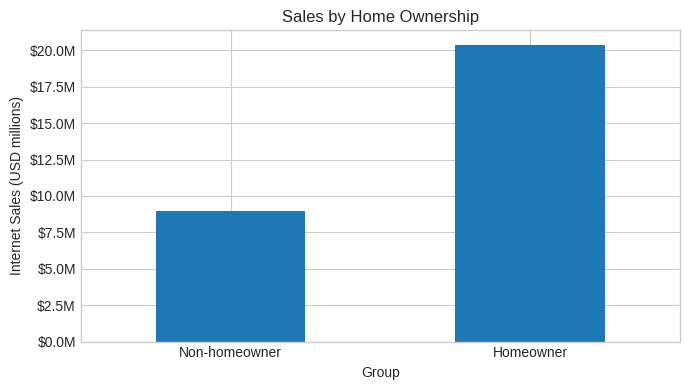

In [9]:
home_sales = (analysis.groupby('HouseOwnerFlag')
    .agg(Sales=('Sales Amount','sum'), Lines=('Sales Amount','size'), Orders=('Sales Order Number','nunique'), Customers=('CustomerKey','nunique'), Avg_Line=('Sales Amount','mean'))
    .reset_index())
home_sales['Group'] = np.where(home_sales['HouseOwnerFlag'].eq(1), 'Homeowner', 'Non-homeowner')
home_sales['Avg_Order'] = home_sales['Sales'] / home_sales['Orders']
display(home_sales[['Group','Sales','Lines','Orders','Customers','Avg_Line','Avg_Order']])
fig, ax = plt.subplots(figsize=(7, 4))
home_sales.plot.bar(x='Group', y='Sales', legend=False, ax=ax, title='Sales by Home Ownership')
ax.set_ylabel('Internet Sales (USD millions)')
ax.tick_params(axis='x', labelrotation=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x/1_000_000:.1f}M'))
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'home_ownership_sales.png', dpi=200, bbox_inches='tight')
plt.show()